# Position Sizing and Risk Management for Systematic Trading

ISMF Algo-Trading Bootcamp — Dylan Sinnott

We compare three ways of sizing the same trading signal:

1. Fixed 10% allocation.
2. Volatility-based sizing with a 2% annual standalone risk target.
3. The same volatility-based sizing with a 20% position cap.

We use reproducible synthetic data to illustrate the mechanics.
The results are not evidence of a profitable trading strategy.

## How to use this notebook

Run the cells from top to bottom.

Requirements: Python, NumPy, pandas and Matplotlib.

The example uses one synthetic asset and a constant long signal.
This isolates the effect of position sizing from signal generation.

All three methods use the same prices, execution timing and cost model.
The 2% target refers to annual standalone volatility relative to portfolio
equity. It is not a maximum loss.

The illustrative limits and parameters are purely hypothetical examples.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Model settings
TRADING_DAYS = 252
LOOKBACK = 60
INITIAL_EQUITY = 100_000
RISK_TARGET = 0.02
FIXED_WEIGHT = 0.10
POSITION_CAP = 0.20
COST_RATE = 0.001  # Illustrative one-way cost: 10 basis points

# Save exported charts here
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Match the presentation
BG = "#0E1525"
WHITE = "#F5F7FA"
GREY = "#B4BDCB"
BLUE = "#4EA5F5"
GREEN = "#36C99B"
RED = "#F16B75"

plt.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": BG,
    "axes.edgecolor": GREY,
    "axes.labelcolor": WHITE,
    "text.color": WHITE,
    "xtick.color": GREY,
    "ytick.color": GREY,
    "grid.color": "#344256",
    "font.size": 12,
    "savefig.facecolor": BG,
})

print("Setup complete.")

Setup complete.


## 1. Synthetic market data

We simulate three consecutive volatility regimes:
- Low volatility: 5% annualised.
- Moderate volatility: 20% annualised.
- High volatility: 40% annualised.

These are simulation inputs, not values supplied to the sizing rule.
The strategy must estimate volatility from observed past returns.

We hold the signal constant at +1 (long) to isolate the effect of sizing.

In [ ]:
# Fix the seed so the example reproduces the same simulated path.
# The seed is not selected to optimise strategy performance.

rng = np.random.default_rng(42)

days_per_regime = 252

# Simulation inputs change in three regimes.
# The sizing rule cannot observe these inputs; it uses rolling estimates.
annual_vol = np.repeat(
    [0.05, 0.20, 0.40],
    days_per_regime
)

n_days = len(annual_vol)

# Include an initial price before the first simulated return
dates = pd.bdate_range("2023-01-02", periods=n_days + 1)

# Zero expected daily return: no predictive edge is assumed
simulated_returns = rng.normal(
    loc=0.0,
    scale=annual_vol / np.sqrt(TRADING_DAYS)
)

prices = pd.Series(
    np.r_[50.0, 50.0 * np.cumprod(1 + simulated_returns)],
    index=dates,
    name="price"
)

data = prices.to_frame()
data["return"] = data["price"].pct_change()
data["input_annual_vol"] = np.r_[np.nan, annual_vol]

# Keep direction constant to isolate sizing behaviour.
# No predictive trading edge is assumed.
data["signal"] = 1.0

# Estimate volatility from the latest 60 observed daily returns.
# Annualise using the same 252-day convention as the risk target.
data["estimated_annual_vol"] = (
    data["return"]
    .rolling(LOOKBACK, min_periods=LOOKBACK)
    .std(ddof=1)
    * np.sqrt(TRADING_DAYS)
)

data.tail()

,price,return,input_annual_vol,signal,estimated_annual_vol
2025-11-19,23.130693,-0.007541,0.4,1.0,0.406294
2025-11-20,22.539072,-0.025577,0.4,1.0,0.403261
2025-11-21,23.702624,0.051624,0.4,1.0,0.407309
2025-11-24,24.768816,0.044982,0.4,1.0,0.418694
2025-11-25,25.477841,0.028626,0.4,1.0,0.422696


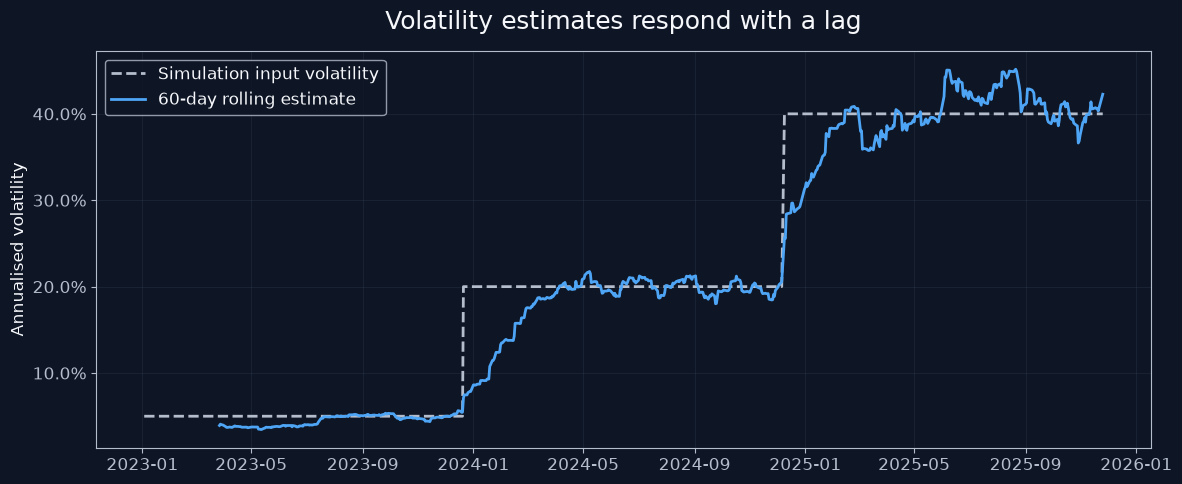

In [3]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    data.index,
    data["input_annual_vol"],
    color=GREY,
    linestyle="--",
    linewidth=2,
    label="Simulation input volatility"
)

ax.plot(
    data.index,
    data["estimated_annual_vol"],
    color=BLUE,
    linewidth=2,
    label="60-day rolling estimate"
)

ax.set_title("Volatility estimates respond with a lag", fontsize=18, pad=16)
ax.set_ylabel("Annualised volatility")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(alpha=0.3)
ax.legend(
    facecolor=BG,
    edgecolor=GREY,
    labelcolor=WHITE
)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "rolling_volatility.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

### Interpretation

The rolling estimate responds gradually to regime changes because its
window contains both older and newer observations.

The dashed line is known only because we generated the data.
In a real market, the underlying volatility is not directly observable.

A shorter lookback responds faster but produces a noisier estimate.
A longer lookback is smoother but reacts more slowly.

## 2. From volatility estimates to target weights

We compare:
- A fixed 10% allocation.
- A 2% annual standalone risk target divided by estimated volatility.
- The same volatility sizing, capped at 20%.

All methods stay in cash until the 60-return estimation window is available.
These are target weights calculated at each observation, before execution.

In [ ]:
# Only size positions when the volatility estimate is valid.
# Require a complete lookback window and a positive volatility estimate.
# All methods remain in cash until this condition is met.
valid_vol = (
    data["estimated_annual_vol"].notna()
    & (data["estimated_annual_vol"] > 0)
)

target_weights = pd.DataFrame(index=data.index)

target_weights["Fixed allocation"] = (
    FIXED_WEIGHT * data["signal"]
).where(valid_vol, 0.0)

target_weights["Volatility sizing"] = (
    data["signal"]
    * RISK_TARGET
    / data["estimated_annual_vol"].where(valid_vol)
).fillna(0.0)

# Limit the magnitude of the target weight to 20%.
# When this binds, the original standalone volatility target is not met.
target_weights["Volatility sizing + cap"] = (
    target_weights["Volatility sizing"]
    .clip(lower=-POSITION_CAP, upper=POSITION_CAP)
)

target_weights.tail().round(4)

,Fixed allocation,Volatility sizing,Volatility sizing + cap
2025-11-19,0.1,0.0492,0.0492
2025-11-20,0.1,0.0496,0.0496
2025-11-21,0.1,0.0491,0.0491
2025-11-24,0.1,0.0478,0.0478
2025-11-25,0.1,0.0473,0.0473


### Interpretation

The fixed method targets 10% throughout the evaluation period.

Volatility sizing increases exposure when estimated volatility is low
and reduces it when estimated volatility is high.

The capped method limits target exposure to 20%.
Its line overlaps the unconstrained method whenever the cap does not bind.

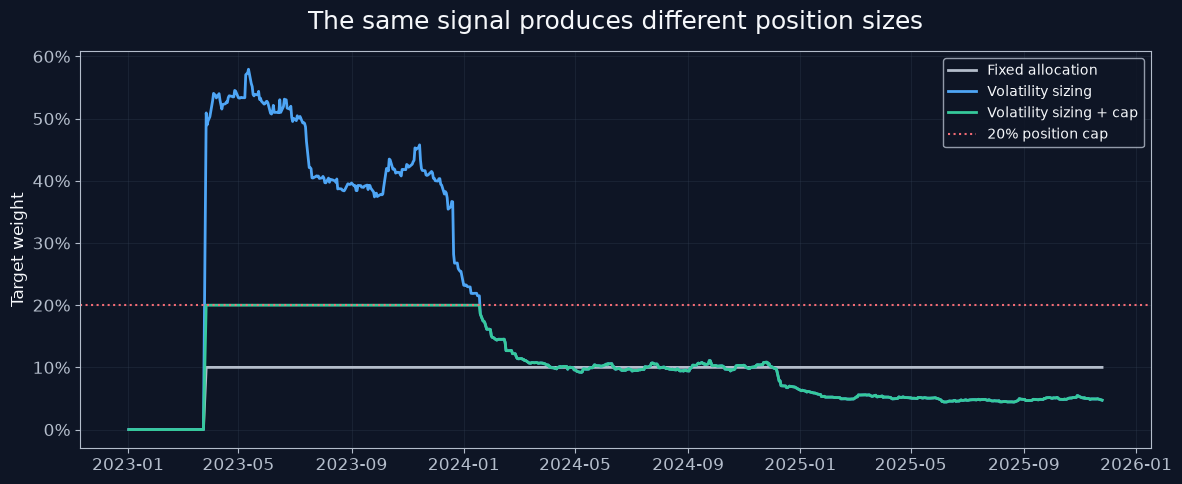

In [5]:
colours = {
    "Fixed allocation": GREY,
    "Volatility sizing": BLUE,
    "Volatility sizing + cap": GREEN,
}

fig, ax = plt.subplots(figsize=(12, 5))

for method in target_weights.columns:
    ax.plot(
        target_weights.index,
        target_weights[method],
        color=colours[method],
        linewidth=2,
        label=method
    )

ax.axhline(
    POSITION_CAP,
    color=RED,
    linestyle=":",
    linewidth=1.5,
    label="20% position cap"
)

ax.set_title(
    "The same signal produces different position sizes",
    fontsize=18,
    pad=16
)
ax.set_ylabel("Target weight")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(alpha=0.3)

ax.legend(
    facecolor=BG,
    edgecolor=GREY,
    labelcolor=WHITE,
    fontsize=10
)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "target_weights.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [6]:
cap_binds = (
    target_weights["Volatility sizing"].abs() > POSITION_CAP
)

print(
    "Cap binds on "
    f"{cap_binds.loc[valid_vol].mean():.1%} "
    "of valid sizing dates."
)

assert np.isfinite(target_weights.to_numpy()).all()

assert (
    target_weights["Volatility sizing + cap"].abs()
    <= POSITION_CAP + 1e-12
).all()

print("Checks passed.")

Cap binds on 30.7% of valid sizing dates.
Checks passed.


## 3. Execution, costs and portfolio performance

Timing:
- Calculate each target using information available after the close.
- Execute it at the following day's close.
- The new holding earns returns after execution.

Assumptions:
- Fractional shares and full fills are permitted.
- Execution costs equal 0.1% of absolute traded value.
- Cash earns no interest.
- Financing costs, market impact and taxes are excluded.
- Targets are sized using equity immediately before execution costs.
- Positions remain open at the end; no final liquidation cost is charged.

### Timing example

1. After Monday's close: calculate a target using information through Monday.
2. At Tuesday's close: execute that target.
3. From Tuesday's close to Wednesday's close: the new holding earns its
   first price return.

Tuesday's closing price is used as the assumed execution price.
Full execution at that price is a modelling assumption.

In [ ]:
def run_backtest(prices, targets):
    cash = float(INITIAL_EQUITY)
    shares = 0.0
    previous_equity = float(INITIAL_EQUITY)
    records = []

    # Execute yesterday's target at today's close.
    # Existing shares earn the price move into today's close;
    # newly purchased shares earn price changes only after execution.
    execution_targets = targets.shift(1).fillna(0.0)

    for date, price in prices.items():
        # Mark existing holdings to today's closing price
        equity_before_cost = cash + shares * price

        # Calculate the desired shares using pre-cost equity
        weight = execution_targets.loc[date]
        # Size using equity before costs. Costs slightly change the resulting post-trade weight, so the cap is a target-weight cap in this example.
        desired_shares = weight * equity_before_cost / price

        # Trade the difference from actual holdings, including price-driven drift.
        # A constant target weight can therefore still require rebalancing.
        trade_shares = desired_shares - shares
        trade_value = trade_shares * price
        cost = abs(trade_value) * COST_RATE

        # Execute the trade and pay its cost
        cash -= trade_value + cost
        shares = desired_shares

        equity = cash + shares * price

        records.append({
            "date": date,
            "equity": equity,
            "net_return": equity / previous_equity - 1,
            "turnover": abs(trade_value) / equity_before_cost,
            "cost": cost,
            "shares": shares,
            "actual_weight": shares * price / equity,
        })

        previous_equity = equity

    result = pd.DataFrame(records).set_index("date")

    # Positive drawdown convention, matching the slides
    result["drawdown"] = (
        1 - result["equity"] / result["equity"].cummax()
    )

    return result


backtests = {
    method: run_backtest(data["price"], target_weights[method])
    for method in target_weights.columns
}

print("All three backtests completed.")

All three backtests completed.


## 4. Performance metrics

- Total net return: change in equity over the simulation, after execution costs.
- Annualised volatility: sample standard deviation of daily net returns
  multiplied by the square root of 252.
- Maximum drawdown: largest percentage decline from a previous equity peak.
  Drawdown is reported as a positive loss percentage.
- Annualised turnover: average daily absolute traded value divided by
  pre-trade equity, multiplied by 252. Purchases and sales both count.
- Total costs: sum of modelled execution costs in euros.

Volatility and turnover use the common evaluation period beginning on
the first execution date. Initial entry costs are included.
No final liquidation is performed.

In [8]:
first_target_date = data.index[valid_vol][0]
first_target_position = data.index.get_loc(first_target_date)
evaluation_start = data.index[first_target_position + 1]

summary_rows = []

for method, result in backtests.items():
    evaluated = result.loc[evaluation_start:]

    summary_rows.append({
        "Method": method,
        "Total net return": (
            result["equity"].iloc[-1] / INITIAL_EQUITY - 1
        ),
        "Annualised volatility": (
            evaluated["net_return"].std(ddof=1)
            * np.sqrt(TRADING_DAYS)
        ),
        "Maximum drawdown": result["drawdown"].max(),
        "Annualised turnover": (
            evaluated["turnover"].mean() * TRADING_DAYS
        ),
        "Total costs (€)": result["cost"].sum(),
    })

summary = pd.DataFrame(summary_rows).set_index("Method")

display_summary = summary.copy()

percentage_columns = [
    "Total net return",
    "Annualised volatility",
    "Maximum drawdown",
    "Annualised turnover",
]

for column in percentage_columns:
    display_summary[column] = summary[column].map(
        lambda value: f"{value:.2%}"
    )

display_summary["Total costs (€)"] = (
    summary["Total costs (€)"].map(lambda value: f"€{value:,.2f}")
)

display(display_summary)

summary.to_csv(OUTPUT_DIR / "comparison_metrics.csv")

,Total net return,Annualised volatility,Maximum drawdown,Annualised turnover,Total costs (€)
Method,,,,,
Fixed allocation,-5.76%,2.78%,8.53%,30.53%,€83.06
Volatility sizing,-4.33%,2.32%,5.26%,89.30%,€243.48
Volatility sizing + cap,-3.09%,2.01%,5.19%,37.34%,€102.71


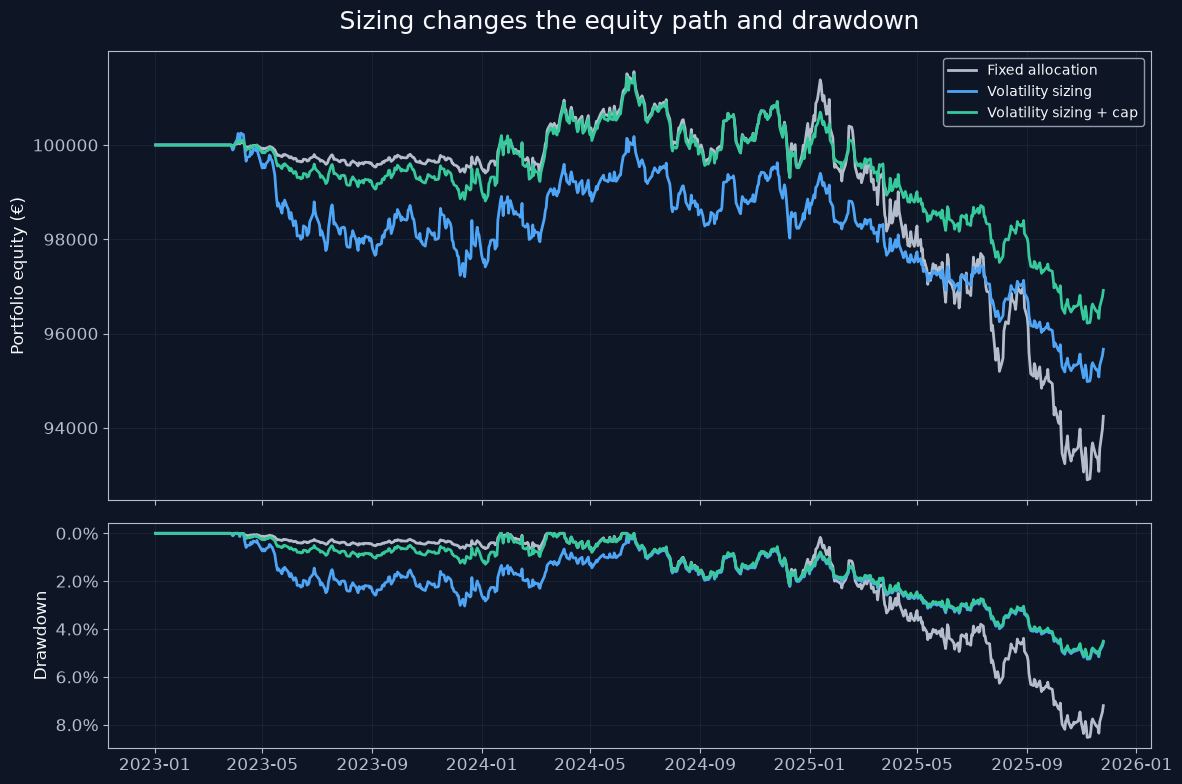

In [9]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}
)

for method, result in backtests.items():
    axes[0].plot(
        result.index,
        result["equity"],
        color=colours[method],
        linewidth=2,
        label=method
    )

    axes[1].plot(
        result.index,
        result["drawdown"],
        color=colours[method],
        linewidth=2
    )

axes[0].set_title(
    "Sizing changes the equity path and drawdown",
    fontsize=18,
    pad=16
)
axes[0].set_ylabel("Portfolio equity (€)")
axes[1].set_ylabel("Drawdown")
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))

# Larger drawdowns appear lower on the chart
axes[1].invert_yaxis()

for ax in axes:
    ax.grid(alpha=0.3)

axes[0].legend(
    facecolor=BG,
    edgecolor=GREY,
    labelcolor=WHITE,
    fontsize=10
)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "equity_and_drawdown.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [10]:
for method, result in backtests.items():
    assert np.isfinite(
        result[["equity", "net_return", "turnover"]].to_numpy()
    ).all()

    assert (result["equity"] > 0).all()
    assert (result["cost"] >= 0).all()
    assert (result["drawdown"] >= -1e-12).all()

    # No holdings before the first executable target
    assert (
        result.loc[result.index < evaluation_start, "shares"] == 0
    ).all()

print("Checks passed.")

Checks passed.


## 5. Findings and limitations

On this simulated path, volatility sizing reduced realised volatility
and maximum drawdown relative to the fixed allocation, but increased turnover.

The position cap reduced low-volatility exposure and turnover relative
to unconstrained volatility sizing.

All three methods lost money. Position sizing changes risk exposure;
it does not create a predictive edge.

These results come from one synthetic path. They do not establish that
one method is consistently superior. Average exposures differ across methods.

The model excludes jumps, changing liquidity, partial fills, financing,
taxes and realistic market impact. Cash earns no interest.

The notebook implements single-asset sizing and a position cap.
It does not implement the lecture's sector limits, multi-asset correlation
checks, portfolio leverage limits or drawdown-response policies.